In [1]:
import os
import glob
import numpy as np
import pandas as pd
from tqdm import tqdm
import matplotlib.pyplot as plt
from matplotlib.lines import Line2D
from scipy.optimize import curve_fit
from scipy.fft import dct
from astropy.timeseries import LombScargle
import warnings

warnings.filterwarnings('ignore')

# ----------------------------------------------------------------------------
# 1. CONFIGURATION
# ----------------------------------------------------------------------------
base_dir = r"ztffp_final_data_2025"
csv_meta_path = r"Cross_15_luiz.csv"

BANDS_TO_PROCESS = ['g']

# Daily cadence in rest-frame -> Nyquist frequency = 1 / (2 * 1.0 d) = 0.5 d^-1
CADENCE_DAYS = 1.0
F_MAX_NYQUIST = 1.0 / (2.0 * CADENCE_DAYS)  # 0.5 day^-1
SEASON_GAP_DAYS = 30.0                      # Gap > 30 days splits seasons
MIN_SEASON_POINTS = 10                      # Minimum observed days in a season
MAX_INTERP_FRACTION = 0.85                  # Max allowed empty fraction in 1-day grid

Z_MIN, Z_MAX = 0.4, 0.5
mass_edges = [7.0, 7.5, 8.0, 8.5, 9.0, 9.5, 10.0]
edd_edges = [-2.5, -2.0, -1.5, -1.0, -0.5, 0.0, 0.5]

N_BINS_FREQ = 40
MIN_OBJS_PER_BIN = 50
N_BOOTSTRAP = 200

cmap = plt.get_cmap('tab10')


# ----------------------------------------------------------------------------
# 2. CORE FUNCTIONS (Nightly Coadd, Seasonal DCT & Calibrated Lomb-Scargle)
# ----------------------------------------------------------------------------

def coadd_nightly_observations(t_obs, f_obs, f_err):
    """
    Group same-night observations using inverse-variance weighted mean
    following Stone et al. (2022) to ensure minimum observed cadence >= 1 day.
    """
    day_ids = np.floor(t_obs).astype(int)
    unique_days = np.unique(day_ids)

    t_daily = np.empty(len(unique_days), dtype=float)
    f_daily = np.empty(len(unique_days), dtype=float)
    err_daily = np.empty(len(unique_days), dtype=float)

    for idx, d in enumerate(unique_days):
        mask = (day_ids == d)
        if np.sum(mask) == 1:
            t_daily[idx] = t_obs[mask][0]
            f_daily[idx] = f_obs[mask][0]
            err_daily[idx] = f_err[mask][0]
        else:
            t_daily[idx] = np.mean(t_obs[mask])
            valid_err = f_err[mask] > 0
            if np.all(valid_err):
                weights = 1.0 / (f_err[mask] ** 2)
                f_daily[idx] = np.sum(weights * f_obs[mask]) / np.sum(weights)
                err_daily[idx] = 1.0 / np.sqrt(np.sum(weights))
            else:
                f_daily[idx] = np.mean(f_obs[mask])
                err_daily[idx] = np.std(f_obs[mask], ddof=1) / np.sqrt(np.sum(mask))

    return t_daily, f_daily, err_daily


def build_daily_season_grid(t_s, f_s, cadence_days=CADENCE_DAYS):
    """
    Linearly interpolate a single observing season onto a uniform 1-day rest-frame grid.
    """
    if len(t_s) < MIN_SEASON_POINTS:
        return None, None

    t_start, t_end = t_s.min(), t_s.max()
    n_bins = int(np.floor((t_end - t_start) / cadence_days)) + 1
    if n_bins < MIN_SEASON_POINTS:
        return None, None

    frac_empty = 1.0 - (len(t_s) / float(n_bins))
    if frac_empty > MAX_INTERP_FRACTION:
        return None, None

    t_grid = t_start + np.arange(n_bins) * cadence_days
    f_interp = np.interp(t_grid, t_s, f_s)
    f_interp = f_interp - np.mean(f_interp)

    return t_grid, f_interp


def compute_seasonal_dct_psd(f_grid, cadence_days=CADENCE_DAYS):
    """
    Compute single-season one-sided PSD via Type-II Orthonormal DCT in [day] units,
    satisfying Parseval's theorem: sum(P(f) * df) = variance.
    """
    N = len(f_grid)
    if N < 4:
        return None, None

    coeffs = dct(f_grid, type=2, norm='ortho')
    freqs = np.arange(1, N) / (2.0 * N * cadence_days)

    valid = freqs <= (1.0 / (2.0 * cadence_days))
    freqs = freqs[valid]
    power = (coeffs[1:][valid] ** 2) * (2.0 * cadence_days)

    return freqs, power


def compute_calibrated_ls_psd(t_rest, flux_norm, f_min, f_max, T_total, samples_per_peak=5):
    """
    Compute Lomb-Scargle periodogram using Astropy's unnormalized 'psd' convention
    (without heteroscedastic weights) and rescale by (2 * T_total / N^2) to match
    the physical [day] units and Parseval normalization of the seasonal DCT.
    """
    N_points = len(t_rest)
    ls = LombScargle(t_rest, flux_norm, fit_mean=True, center_data=True)
    freqs, p_astropy_psd = ls.autopower(
        normalization='psd',
        minimum_frequency=f_min,
        maximum_frequency=f_max,
        samples_per_peak=samples_per_peak
    )
    # Rescale to one-sided PSD in [day] units (independent of samples_per_peak)
    power_psd = p_astropy_psd * (2.0 * T_total / (N_points ** 2))
    return freqs, power_psd


def bin_psd_to_grid(freqs, powers, bin_edges):
    """
    Project discrete periodogram estimates onto the global logarithmic frequency bins
    by averaging all frequencies falling inside each bin.
    """
    n_bins = len(bin_edges) - 1
    binned = np.full(n_bins, np.nan)
    inds = np.searchsorted(bin_edges, freqs, side='right') - 1
    valid = (inds >= 0) & (inds < n_bins) & np.isfinite(powers) & (powers > 0)
    if not np.any(valid):
        return binned

    bid, pw = inds[valid], powers[valid]
    sums = np.bincount(bid, weights=pw, minlength=n_bins)
    counts = np.bincount(bid, minlength=n_bins)
    mask = counts > 0
    binned[mask] = sums[mask] / counts[mask]
    return binned


def compute_hybrid_object_psd(d, bin_edges):
    """
    Construct the full broad-band PSD for a single quasar on the common log-frequency grid:
    1. High-frequency regime: 1-day interpolated seasonal DCT, binned onto `bin_edges`,
       taking the median across seasons.
    2. Dynamic cutoff `f_cut`: lower edge of the first bin populated by the seasonal DCT.
    3. Low-frequency regime: calibrated Lomb-Scargle evaluated strictly below `f_cut`.
    """
    season_binned_list = []

    # --- STEP 1: High-frequency seasonal DCT ---
    for t_s, f_s in zip(d['seasons_t'], d['seasons_f_norm']):
        t_grid, f_grid = build_daily_season_grid(t_s, f_s, cadence_days=CADENCE_DAYS)
        if t_grid is None:
            continue
        freqs_s, power_s = compute_seasonal_dct_psd(f_grid, cadence_days=CADENCE_DAYS)
        if freqs_s is not None and len(freqs_s) > 0:
            binned_s = bin_psd_to_grid(freqs_s, power_s, bin_edges)
            season_binned_list.append(binned_s)

    if len(season_binned_list) == 0:
        return None, np.nan

    season_matrix = np.vstack(season_binned_list)
    psd_high_binned = np.nanmedian(season_matrix, axis=0)

    valid_hi_bins = np.where(np.isfinite(psd_high_binned))[0]
    if len(valid_hi_bins) == 0:
        return None, np.nan

    # --- STEP 2: Dynamic f_cut ---
    first_hi_bin_idx = valid_hi_bins[0]
    f_cut = bin_edges[first_hi_bin_idx]

    # --- STEP 3: Low-frequency Lomb-Scargle strictly below f_cut ---
    f_min_obj = 1.0 / d['T_total']
    psd_hybrid_binned = psd_high_binned.copy()

    if f_min_obj < f_cut:
        try:
            f_ls, p_ls_psd = compute_calibrated_ls_psd(
                d['t_rest'], d['flux_norm'],
                f_min=f_min_obj,
                f_max=min(f_cut, F_MAX_NYQUIST),
                T_total=d['T_total'],
                samples_per_peak=5
            )
            lo_mask = f_ls < f_cut
            if np.any(lo_mask):
                psd_low_binned = bin_psd_to_grid(f_ls[lo_mask], p_ls_psd[lo_mask], bin_edges)
                low_bin_indices = np.arange(0, first_hi_bin_idx)
                psd_hybrid_binned[low_bin_indices] = psd_low_binned[low_bin_indices]
        except Exception:
            pass

    return psd_hybrid_binned, f_cut


def bending_pl_petrecca(f, PSD_norm, nu_b, alpha_high, C_noise):
    """
    Bending Power Law (BPL) model from Petrecca et al. (2026), Eq. 3,
    with low-frequency slope fixed at alpha_low = -1.0.
    """
    alpha_diff = -1.0 - alpha_high
    term = (1.0 + (f / nu_b) ** alpha_diff) ** (-1.0)
    return PSD_norm * (f ** (-1.0)) * term + C_noise


def fit_bending_pl_petrecca(freq, power, fix_alpha_high=None):
    mask = (power > 0) & np.isfinite(power) & np.isfinite(freq) & (freq > 0)
    if np.sum(mask) < 5:
        return None
    f_fit, p_fit = freq[mask], power[mask]

    try:
        if fix_alpha_high is None:
            p0 = [np.median(p_fit * f_fit), 1e-3, -2.7, np.min(p_fit) * 0.1]
            bounds = ([1e-10, 1e-6, -5.0, 0.0], [10.0, 0.2, -1.0, np.max(p_fit)])
            popt, _ = curve_fit(bending_pl_petrecca, f_fit, p_fit, p0=p0, bounds=bounds, maxfev=5000)
            return {'PSD_norm': popt[0], 'nu_b': popt[1], 'alpha_high': popt[2], 'C_noise': popt[3]}
        else:
            def model_fixed(f, PSD_norm, nu_b, C_noise):
                return bending_pl_petrecca(f, PSD_norm, nu_b, fix_alpha_high, C_noise)
            p0 = [np.median(p_fit * f_fit), 1e-3, np.min(p_fit) * 0.1]
            bounds = ([1e-10, 1e-6, 0.0], [10.0, 0.2, np.max(p_fit)])
            popt, _ = curve_fit(model_fixed, f_fit, p_fit, p0=p0, bounds=bounds, maxfev=5000)
            return {'PSD_norm': popt[0], 'nu_b': popt[1], 'alpha_high': fix_alpha_high, 'C_noise': popt[2]}
    except Exception:
        return None


def bootstrap_psd(matrix, n_boot=N_BOOTSTRAP):
    n = matrix.shape[0]
    if n < 2:
        return np.nanmedian(matrix, axis=0), np.zeros(matrix.shape[1])
    samples = []
    for _ in range(n_boot):
        idx = np.random.choice(n, size=n, replace=True)
        samples.append(np.nanmedian(matrix[idx, :], axis=0))
    samples = np.array(samples)
    return np.nanmedian(samples, axis=0), np.nanstd(samples, axis=0)


# ----------------------------------------------------------------------------
# 3. PLOTTING FUNCTIONS
# ----------------------------------------------------------------------------

def plot_distribution_grid(LOGMBH_arr, LOGLEDD_arr, band, plots_dir):
    """Figure 1: BH Mass vs Eddington Ratio object count grid."""
    fig, ax = plt.subplots(figsize=(10, 8))

    H, xedges, yedges = np.histogram2d(LOGMBH_arr, LOGLEDD_arr, bins=(mass_edges, edd_edges))
    X, Y = np.meshgrid(xedges, yedges)

    pc = ax.pcolormesh(X, Y, H.T, cmap='Blues', edgecolors='black', linewidth=1, alpha=0.8)

    for i in range(len(mass_edges) - 1):
        for j in range(len(edd_edges) - 1):
            count = int(H[i, j])
            if count > 0:
                color = 'white' if count > np.max(H) / 2 else 'black'
                ax.text((mass_edges[i] + mass_edges[i + 1]) / 2,
                        (edd_edges[j] + edd_edges[j + 1]) / 2,
                        str(count), ha='center', va='center',
                        color=color, fontweight='bold', fontsize=12)

    ax.set_xlabel(r'$\log M_{\rm BH}$', fontweight='bold', fontsize=14)
    ax.set_ylabel(r'$\log \lambda_{\rm Edd}$', fontweight='bold', fontsize=14)
    ax.set_title(f'Object Distribution (Band {band.upper()})', fontweight='bold', fontsize=16)
    ax.set_xticks(mass_edges)
    ax.set_yticks(edd_edges)

    cbar = plt.colorbar(pc, ax=ax)
    cbar.set_label('Number of Objects', fontweight='bold', fontsize=12)

    plt.tight_layout()
    plt.savefig(os.path.join(plots_dir, f'Grid_Mass_Edd_band_{band}.png'), dpi=200)
    plt.close()


def plot_ensemble_split(LOGMBH_arr, LOGLEDD_arr, binned_matrix_hybrid, binned_matrix_ls,
                        f_cut_arr, bin_centers, band, plots_dir, grouping='Mass'):
    """Figures 2 and 3: Side-by-side Ensemble PSD (Hybrid DCT+LS vs Pure LS)."""
    fig, (ax_hyb, ax_ls) = plt.subplots(1, 2, figsize=(20, 8), sharey=True)

    mi = np.digitize(LOGMBH_arr, mass_edges) - 1
    ej = np.digitize(LOGLEDD_arr, edd_edges) - 1
    valid = ((mi >= 0) & (mi < len(mass_edges) - 1) & (ej >= 0) & (ej < len(edd_edges) - 1))

    if grouping == 'Mass':
        groups = range(len(mass_edges) - 1)
        arr = mi
        prefix = 'BH Mass'
    else:
        groups = range(len(edd_edges) - 1)
        arr = ej
        prefix = 'Eddington Ratio'

    fit_results = []

    for i, g in enumerate(groups):
        mask = valid & (arr == g)
        idxs = np.where(mask)[0]
        if len(idxs) < MIN_OBJS_PER_BIN:
            continue

        color = cmap(i % cmap.N)
        lbl = (f"{mass_edges[g]:.1f}-{mass_edges[g+1]:.1f} | N={len(idxs)}"
               if grouping == 'Mass' else
               f"{edd_edges[g]:.1f} to {edd_edges[g+1]:.1f} | N={len(idxs)}")

        # --- LEFT PANEL: Hybrid PSD (LS low-freq + Median Seasonal 1-day DCT high-freq) ---
        sub_hyb = binned_matrix_hybrid[idxs, :]
        good_hyb = np.sum(~np.isnan(sub_hyb), axis=0) >= max(3, len(idxs) // 10)
        if np.sum(good_hyb) >= 4:
            med_hyb, std_hyb = bootstrap_psd(sub_hyb[:, good_hyb])
            x_f = bin_centers[good_hyb]

            ax_hyb.loglog(x_f, med_hyb, 'o-', color=color, lw=2, ms=5, label=lbl)
            ax_hyb.fill_between(x_f, np.maximum(med_hyb - std_hyb, 1e-12), med_hyb + std_hyb, color=color, alpha=0.2)

            fit_free = fit_bending_pl_petrecca(x_f, med_hyb, fix_alpha_high=None)
            if fit_free:
                f_th = np.logspace(np.log10(x_f.min()), np.log10(x_f.max()), 100)
                p_th = bending_pl_petrecca(f_th, fit_free['PSD_norm'], fit_free['nu_b'],
                                           fit_free['alpha_high'], fit_free['C_noise'])
                ax_hyb.loglog(f_th, p_th, '--', color=color, alpha=0.8, lw=1.5)

                fit_results.append({
                    'grouping': grouping, 'bin': int(g), 'N_objects': int(len(idxs)),
                    'center': float(np.median(LOGMBH_arr[mask])) if grouping == 'Mass' else float(np.median(LOGLEDD_arr[mask])),
                    'median_f_cut': float(np.nanmedian(f_cut_arr[idxs])),
                    'method': 'Hybrid_LS_DCT', 'nu_b': float(fit_free['nu_b']),
                    'alpha_high': float(fit_free['alpha_high']),
                    'PSD_norm': float(fit_free['PSD_norm']), 'C_noise': float(fit_free['C_noise'])
                })

        # --- RIGHT PANEL: Pure Lomb-Scargle (Nightly Coadded) ---
        sub_ls = binned_matrix_ls[idxs, :]
        good_ls = np.sum(~np.isnan(sub_ls), axis=0) >= max(3, len(idxs) // 10)
        if np.sum(good_ls) >= 4:
            med_ls, std_ls = bootstrap_psd(sub_ls[:, good_ls])
            x_f_ls = bin_centers[good_ls]

            ax_ls.loglog(x_f_ls, med_ls, 's-', color=color, lw=2, ms=5, label=lbl)
            ax_ls.fill_between(x_f_ls, np.maximum(med_ls - std_ls, 1e-12), med_ls + std_ls, color=color, alpha=0.2)

            fit_ls = fit_bending_pl_petrecca(x_f_ls, med_ls, fix_alpha_high=None)
            if fit_ls:
                f_th_ls = np.logspace(np.log10(x_f_ls.min()), np.log10(x_f_ls.max()), 100)
                p_th_ls = bending_pl_petrecca(f_th_ls, fit_ls['PSD_norm'], fit_ls['nu_b'],
                                              fit_ls['alpha_high'], fit_ls['C_noise'])
                ax_ls.loglog(f_th_ls, p_th_ls, ':', color=color, alpha=0.8, lw=1.5)

                fit_results.append({
                    'grouping': grouping, 'bin': int(g), 'N_objects': int(len(idxs)),
                    'center': float(np.median(LOGMBH_arr[mask])) if grouping == 'Mass' else float(np.median(LOGLEDD_arr[mask])),
                    'median_f_cut': float(np.nanmedian(f_cut_arr[idxs])),
                    'method': 'Pure_LS', 'nu_b': float(fit_ls['nu_b']),
                    'alpha_high': float(fit_ls['alpha_high']),
                    'PSD_norm': float(fit_ls['PSD_norm']), 'C_noise': float(fit_ls['C_noise'])
                })

    med_fcut_global = np.nanmedian(f_cut_arr[valid])
    if np.isfinite(med_fcut_global):
        ax_hyb.axvline(med_fcut_global, color='black', ls='-.', alpha=0.6, lw=1.5)

    handles_hyb, labels_hyb = ax_hyb.get_legend_handles_labels()
    handles_hyb.append(Line2D([0], [0], color='gray', lw=2, ls='--'))
    labels_hyb.append('BPL Fit')
    if np.isfinite(med_fcut_global):
        handles_hyb.append(Line2D([0], [0], color='black', lw=1.5, ls='-.'))
        labels_hyb.append(f'Median $f_{{cut}}$ ({med_fcut_global:.3f} d$^{{-1}}$)')
    ax_hyb.legend(handles_hyb, labels_hyb, fontsize=10, loc='lower left')

    handles_ls, labels_ls = ax_ls.get_legend_handles_labels()
    handles_ls.append(Line2D([0], [0], color='gray', lw=2, ls=':'))
    labels_ls.append('BPL Fit')
    ax_ls.legend(handles_ls, labels_ls, fontsize=10, loc='lower left')

    ax_hyb.set_xlabel(r'Rest-Frame Frequency [day$^{-1}$]', fontweight='bold', fontsize=12)
    ax_hyb.set_ylabel('PSD [day]', fontweight='bold', fontsize=12)
    ax_hyb.set_title(f'{prefix} - Hybrid PSD (LS + 1d Seasonal DCT)', fontweight='bold', fontsize=14)
    ax_hyb.grid(ls=':', alpha=0.5, which='both')

    ax_ls.set_xlabel(r'Rest-Frame Frequency [day$^{-1}$]', fontweight='bold', fontsize=12)
    ax_ls.set_title(f'{prefix} - Pure Lomb-Scargle (Nightly Coadded)', fontweight='bold', fontsize=14)
    ax_ls.grid(ls=':', alpha=0.5, which='both')

    plt.suptitle(f"Ensemble PSD Comparison (Band {band.upper()})", fontweight='bold', fontsize=18)
    plt.tight_layout()
    plt.savefig(os.path.join(plots_dir, f'Ensemble_Comparison_{grouping}_band_{band}.png'), dpi=200)
    plt.close()

    return fit_results


# ----------------------------------------------------------------------------
# 4. MAIN PIPELINE
# ----------------------------------------------------------------------------

for band in BANDS_TO_PROCESS:
    print(f"\n{'='*60}")
    print(f" STARTING HYBRID DCT+LS PROCESSING FOR BAND: '{band.upper()}'")
    print(f"{'='*60}")

    plots_dir = f"plots_Hybrid_LS_DCT_band_{band}"
    os.makedirs(plots_dir, exist_ok=True)

    print("Loading metadata...")
    try:
        meta = pd.read_csv(csv_meta_path.replace("\\", "/"))
        ra_cat = meta['RA'].values
        dec_cat = meta['DEC'].values
        logmbh_cat = meta['LOGMBH'].values
        logedd_cat = meta['LOGLEDD_RATIO'].values
        z_col = 'Z_DR16Q' if 'Z_DR16Q' in meta.columns else 'Z'
        z_cat = meta[z_col].values
    except FileNotFoundError:
        print(f"WARNING: Metadata catalog {csv_meta_path} not found.")
        continue

    folders = [f for f in os.listdir(base_dir) if os.path.isdir(os.path.join(base_dir, f)) and "plots" not in f]
    valid_data = []
    n_rej_seasons = n_rej_other = 0

    for folder in tqdm(folders, desc=f"Band {band}"):
        try:
            ra_f, dec_f = map(float, folder.split('_'))
        except Exception:
            continue

        dist = np.sqrt((ra_cat - ra_f) ** 2 + (dec_cat - dec_f) ** 2)
        idx = np.argmin(dist)
        if dist[idx] > 1e-4:
            continue

        m, e, z = logmbh_cat[idx], logedd_cat[idx], z_cat[idx]
        if np.isnan(m) or np.isnan(e) or np.isnan(z):
            continue
        if z < Z_MIN or z > Z_MAX:
            continue
        if m < mass_edges[0] or m >= mass_edges[-1]:
            continue
        if e < edd_edges[0] or e >= edd_edges[-1]:
            continue

        txt_files = glob.glob(os.path.join(base_dir, folder, f"*_ztf_{band}_filtered.txt"))
        if not txt_files:
            continue

        try:
            df = pd.read_csv(txt_files[0]).sort_values('mjd')
            if len(df) < 20 or 'mjd' not in df.columns or 'flux' not in df.columns:
                continue

            t_raw = df['mjd'].values
            f_raw = df['flux'].values
            err_raw = df['fluxe'].values if 'fluxe' in df.columns else np.zeros_like(f_raw)

            # 1. Nightly coadd: replace same-day measurements with daily mean flux
            t_obs, f_obs, f_err = coadd_nightly_observations(t_raw, f_raw, err_raw)
            if len(t_obs) < 15:
                continue

            # 2. Shift to rest frame
            t_ref = t_obs.min()
            t_rest = (t_obs - t_ref) / (1.0 + z)
            T_total_rest = t_rest.max() - t_rest.min()

            # 3. Fractional flux normalization
            f_med = np.median(f_obs)
            f_norm = (f_obs - f_med) / f_med
            f_err_norm = f_err / f_med

            # 4. Split seasons whenever gap > 30 days
            gaps_rest = np.diff(t_rest)
            breaks = np.where(gaps_rest > (SEASON_GAP_DAYS / (1.0 + z)))[0] + 1
            season_idx = np.split(np.arange(len(t_rest)), breaks)

            seasons_t, seasons_f, seasons_f_err = [], [], []
            for s in season_idx:
                if len(s) >= MIN_SEASON_POINTS:
                    ts_, fs_, ferr_ = t_rest[s], f_norm[s], f_err_norm[s]
                    t_g, f_g = build_daily_season_grid(ts_, fs_, cadence_days=CADENCE_DAYS)
                    if t_g is not None:
                        seasons_t.append(ts_)
                        seasons_f.append(fs_)
                        seasons_f_err.append(ferr_)

            if len(seasons_t) < 2:
                n_rej_seasons += 1
                continue

            valid_data.append({
                't_obs': t_obs, 't_rest': t_rest,
                'flux_norm': f_norm, 'flux_err_norm': f_err_norm,
                'seasons_t': seasons_t,
                'seasons_f_norm': seasons_f,
                'seasons_f_err': seasons_f_err,
                'T_total': T_total_rest,
                'LOGMBH': m, 'LOGLEDD_RATIO': e, 'Z': z
            })
        except Exception:
            n_rej_other += 1
            continue

    print(f"Total valid quasars: {len(valid_data)} (Rejected seasons: {n_rej_seasons})")
    if not valid_data:
        continue

    # --- Global Logarithmic Frequency Grid ---
    global_fmin = 1.0 / max([d['T_total'] for d in valid_data])
    bin_edges = np.logspace(np.log10(global_fmin), np.log10(F_MAX_NYQUIST), N_BINS_FREQ + 1)
    bin_centers = np.sqrt(bin_edges[:-1] * bin_edges[1:])

    binned_matrix_hybrid = np.full((len(valid_data), N_BINS_FREQ), np.nan)
    binned_matrix_ls = np.full((len(valid_data), N_BINS_FREQ), np.nan)
    f_cut_arr = np.full(len(valid_data), np.nan)

    for i, d in enumerate(valid_data):
        # 1. Pure Calibrated Lomb-Scargle (for right-panel comparison)
        try:
            f_min_obj = 1.0 / d['T_total']
            f_ls, p_ls_psd = compute_calibrated_ls_psd(
                d['t_rest'], d['flux_norm'],
                f_min=f_min_obj,
                f_max=F_MAX_NYQUIST,
                T_total=d['T_total'],
                samples_per_peak=5
            )
            binned_matrix_ls[i, :] = bin_psd_to_grid(f_ls, p_ls_psd, bin_edges)
        except Exception:
            pass

        # 2. Hybrid PSD: Median 1-day Seasonal DCT (high-freq) + Calibrated LS < f_cut (low-freq)
        psd_hyb, f_cut_obj = compute_hybrid_object_psd(d, bin_edges)
        if psd_hyb is not None:
            binned_matrix_hybrid[i, :] = psd_hyb
            f_cut_arr[i] = f_cut_obj

    LOGMBH_arr = np.array([d['LOGMBH'] for d in valid_data])
    LOGLEDD_arr = np.array([d['LOGLEDD_RATIO'] for d in valid_data])

    # --- GENERATE FIGURES ---
    print("Generating Figure 1: Object Distribution Grid...")
    plot_distribution_grid(LOGMBH_arr, LOGLEDD_arr, band, plots_dir)

    print("Generating Figure 2: Ensemble PSD by Mass (Hybrid DCT+LS vs Pure LS)...")
    fits_mass = plot_ensemble_split(
        LOGMBH_arr, LOGLEDD_arr, binned_matrix_hybrid, binned_matrix_ls,
        f_cut_arr, bin_centers, band, plots_dir, grouping='Mass'
    )

    print("Generating Figure 3: Ensemble PSD by Eddington (Hybrid DCT+LS vs Pure LS)...")
    fits_edd = plot_ensemble_split(
        LOGMBH_arr, LOGLEDD_arr, binned_matrix_hybrid, binned_matrix_ls,
        f_cut_arr, bin_centers, band, plots_dir, grouping='Eddington'
    )

    all_fits = fits_mass + fits_edd
    if all_fits:
        df_fits = pd.DataFrame(all_fits)
        df_fits.to_csv(os.path.join(plots_dir, f'Fit_results_Hybrid_band_{band}.csv'), index=False)
        print(f"Results saved to {plots_dir}/Fit_results_Hybrid_band_{band}.csv")

print("\n=== HYBRID DCT+LS PROCESSING COMPLETE ===")


 STARTING HYBRID DCT+LS PROCESSING FOR BAND: 'G'
Loading metadata...


Band g: 100%|██████████| 2261/2261 [00:04<00:00, 482.23it/s]


Total valid quasars: 466 (Rejected seasons: 0)
Generating Figure 1: Object Distribution Grid...
Generating Figure 2: Ensemble PSD by Mass (Hybrid DCT+LS vs Pure LS)...
Generating Figure 3: Ensemble PSD by Eddington (Hybrid DCT+LS vs Pure LS)...
Results saved to plots_Hybrid_LS_DCT_band_g/Fit_results_Hybrid_band_g.csv

=== HYBRID DCT+LS PROCESSING COMPLETE ===


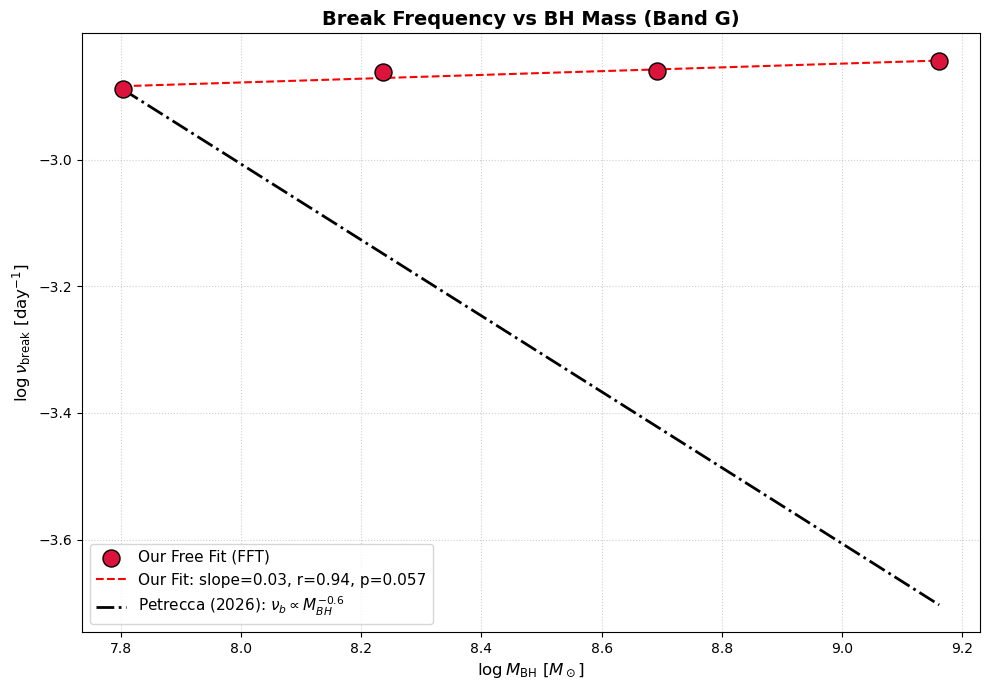

In [2]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
from scipy.stats import pearsonr

# Carregar os resultados salvos pelo pipeline anterior
# (Garanta que o caminho está correto)
df = pd.read_csv('plots_Petrecca_Corrected_band_g/Fit_results_Comparison_band_g.csv')

# Filtrar apenas os resultados por Massa e do método FFT
df_mass = df[(df['grouping'] == 'Mass') & (df['method'] == 'FFT')]

if not df_mass.empty:
    fig, ax = plt.subplots(figsize=(10, 7))
    
    # Nossos dados
    mass = df_mass['center']
    log_nub_free = np.log10(df_mass['nu_b'])
    ax.scatter(mass, log_nub_free, s=150, c='crimson', edgecolor='black', zorder=3, label='Our Free Fit (FFT)')
    
    # Nossa tendência
    coef = np.polyfit(mass, log_nub_free, 1)
    r, p = pearsonr(mass, log_nub_free)
    xs = np.linspace(mass.min(), mass.max(), 100)
    ax.plot(xs, np.polyval(coef, xs), 'r--', label=f'Our Fit: slope={coef[0]:.2f}, r={r:.2f}, p={p:.3f}')

    # Adicionar a previsão do Petrecca (nu_b ~ M^-0.6)
    # Vamos ancorar a linha do Petrecca no centro do nosso primeiro ponto para comparar inclinações
    anchor_x = mass.iloc[0]
    anchor_y = log_nub_free.iloc[0]
    # log(nu_b) = log(nu_b0) - 0.6 * (logM - logM0)
    petrecca_slope = -0.6
    petrecca_line = anchor_y + petrecca_slope * (xs - anchor_x)
    
    ax.plot(xs, petrecca_line, 'k-.', lw=2, label='Petrecca (2026): $\\nu_b \propto M_{BH}^{-0.6}$')
    
    ax.set_xlabel(r'$\log M_{\rm BH} \ [M_\odot]$', fontweight='bold', fontsize=12)
    ax.set_ylabel(r'$\log \nu_{\rm break} \ [\mathrm{day}^{-1}]$', fontweight='bold', fontsize=12)
    ax.set_title('Break Frequency vs BH Mass (Band G)', fontweight='bold', fontsize=14)
    ax.legend(fontsize=11)
    ax.grid(ls=':', alpha=0.6)
    
    plt.tight_layout()
    plt.savefig('Compare_Petrecca_Mass_Nub.png', dpi=200)
    plt.show()
else:
    print("Nenhum resultado de FFT por massa encontrado no CSV.")